# Saúde mental no setor de tecnologia — projeto de aplicação de ML
**Disciplina:** Introdução ao Aprendizado de Máquina para Saúde — UFF  
**Autor:** Daniel Fontoura  
**Fonte:** [OSMI Mental Health in Tech Survey, 2014](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey)

**Pergunta:** características e percepções do ambiente de trabalho permitem classificar retrospectivamente se o respondente **já buscou tratamento** para uma condição de saúde mental? Quanto a discriminação aumenta com informações individuais?

> **Atenção:** `treatment` é autorrelato de busca anterior por tratamento, **não é diagnóstico**, risco de doença ou probabilidade futura validada. Os modelos são apenas exercícios acadêmicos retrospectivos e **não** devem ser aplicados a decisões individuais de RH.

## 1. Dependências, funções de apoio e reprodutibilidade

Ambiente recomendado: Python 3.11+, bibliotecas de `requirements.txt`; executar a partir da raiz do repositório. Uma semente global de 42 fixa os sorteios da divisão dos dados, algoritmos e reamostragem bootstrap. O repositório não contém dados individuais na versão pública.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay
from src.modeling import (SEED, ORGANIZATIONAL, INDIVIDUAL, FULL, FULL_WITHOUT_INTERFERENCE,
    load_dataset, build_pipeline, candidates, evaluate, bootstrap_auc, bootstrap_auc_diff)

np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (8,4.3), 'font.size': 10})
ROOT=Path('.')
OUTPUT=ROOT/'resultados'; OUTPUT.mkdir(exist_ok=True)
FIGS=ROOT/'artigo'/'figuras'; FIGS.mkdir(parents=True, exist_ok=True)
print('Versões:', 'pandas',pd.__version__,'numpy',np.__version__)


Versões: pandas 2.2.3 numpy 2.3.5


## 2. Carregamento e auditoria do dataset

O CSV original possui 27 colunas. O campo `comments` **não é exibido**. Variáveis descartadas da modelagem: `Timestamp` (metadado), `comments` (texto livre sensível), `state`/`Country` (não são fatores organizacionais e podem representar diferenças regionais de acesso) e `Gender` bruto (substituído por agrupamento conservador no modelo ampliado).

A limpeza de idade substitui valores fora de **18 a 90 anos** por ausentes, sem excluir o respondente. Imputação numérica, imputação categórica e codificação One-Hot são **ajustadas somente nos folds de treinamento**, nunca no dataset inteiro.

In [2]:
csv=ROOT/'data'/'survey.csv'
if not csv.exists():
    raise FileNotFoundError('Baixe survey.csv do Kaggle e coloque em data/survey.csv. Consulte data/INSTRUCOES.md.')
raw=pd.read_csv(csv)
df=load_dataset(csv)
y=df['treatment'].map({'No':0,'Yes':1}).astype(int)
print(f'Linhas={len(df)}, colunas originais={raw.shape[1]}, taxa positiva={y.mean():.3f}')
print('Target:\n',raw['treatment'].value_counts().to_string())
print('Idades inválidas substituídas por NaN:',int((~raw['Age'].between(18,90)).sum()))
print('Categorizações distintas de gênero antes/depois:',raw['Gender'].nunique(),df['Gender_group'].nunique())
print('Ausências no CSV original:\n',raw.isna().sum().sort_values(ascending=False).head(7).to_string())
assert y.notna().all() and set(y.unique())=={0,1}


Linhas=1259, colunas originais=27, taxa positiva=0.506
Target:
 treatment
Yes    637
No     622
Idades inválidas substituídas por NaN: 8
Categorizações distintas de gênero antes/depois: 49 3
Ausências no CSV original:
 comments          1095
state              515
work_interfere     264
self_employed       18
Gender               0
Timestamp            0
Age                  0


## 3. Análise exploratória (EDA)

Gráficos agregados, sem divulgar respostas individuais. O equilíbrio do target não elimina viés de **autosseleção** da pesquisa; as frequências não estimam prevalência de doença mental na população de TI.

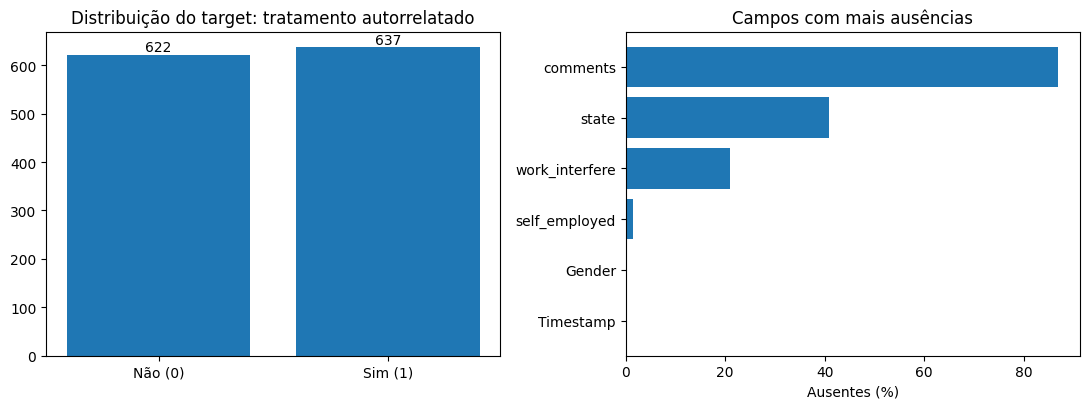


 benefits (contagem / fração Yes):
             size   mean
benefits               
Don't know   408  0.370
No           374  0.484
Yes          477  0.639

 remote_work (contagem / fração Yes):
              size   mean
remote_work             
No            883  0.497
Yes           376  0.527

 care_options (contagem / fração Yes):
               size   mean
care_options             
No             501  0.413
Not sure       314  0.392
Yes            444  0.691

 family_history (contagem / fração Yes):
                 size   mean
family_history             
No               767  0.355
Yes              492  0.742

 work_interfere (contagem / fração Yes):
                 size   mean
work_interfere             
Never            213  0.141
Often            144  0.854
Rarely           173  0.705
Sometimes        465  0.770
NaN              264  0.015


In [3]:
fig, axes=plt.subplots(1,2,figsize=(11,4.2))
counts=y.value_counts().sort_index()
axes[0].bar(['Não (0)','Sim (1)'],counts.values)
axes[0].set_title('Distribuição do target: tratamento autorrelatado')
for i,v in enumerate(counts.values): axes[0].text(i,v+7,str(v),ha='center')
miss=raw.isna().mean().sort_values(ascending=False).head(6)*100
axes[1].barh(miss.index[::-1],miss.values[::-1]);axes[1].set_xlabel('Ausentes (%)');axes[1].set_title('Campos com mais ausências')
plt.tight_layout();fig.savefig(FIGS/'01_eda_dataset.png',dpi=180,bbox_inches='tight');plt.show()

for col in ['benefits','remote_work','care_options','family_history','work_interfere']:
    rate=df.assign(treatment_bin=y).groupby(col,dropna=False)['treatment_bin'].agg(['size','mean'])
    print('\n',col,'(contagem / fração Yes):\n',rate.round(3).to_string())


## 4. Definição dos experimentos e protocolo

**A — Organizacional:** 18 atributos sobre características da empresa, suporte oferecido e **percepções autorrelatadas** do contexto de trabalho. Nem todos refletem políticas objetivas ou medições anteriores à procura por tratamento.

**B — Ampliado:** os mesmos atributos + `Age`, agrupamento de `Gender`, `family_history` e `work_interfere`. A última variável é **condicional** à percepção de ter uma condição mental e tem ausência informativa; por isso uma **ablação** sem `work_interfere` será feita separadamente.

**Validação:** hold-out estratificado 80/20 reservado antes de ajuste; `StratifiedKFold(5)` somente nos 80% de treino; GridSearchCV escolhe hiperparâmetros por AUROC; o teste só é avaliado após seleção. O mesmo conjunto de teste é usado em todos os experimentos. Como não existe identificador de pessoa, não é possível comprovar ausência de respondentes duplicados, o que limita a validação.

In [4]:
print('Atributos organizacionais (A):',ORGANIZATIONAL)
print('Atributos adicionais (B):',INDIVIDUAL)
idx_train,idx_test=train_test_split(np.arange(len(df)),test_size=.20,random_state=SEED,stratify=y)
y_train=y.iloc[idx_train];y_test=y.iloc[idx_test]
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Treino:',len(idx_train),'[No, Yes]=',np.bincount(y_train))
print('Teste:',len(idx_test),'[No, Yes]=',np.bincount(y_test))


Atributos organizacionais (A): ['self_employed', 'no_employees', 'remote_work', 'tech_company', 'benefits', 'care_options', 'wellness_program', 'seek_help', 'anonymity', 'leave', 'mental_health_consequence', 'phys_health_consequence', 'coworkers', 'supervisor', 'mental_health_interview', 'phys_health_interview', 'mental_vs_physical', 'obs_consequence']
Atributos adicionais (B): ['Age', 'Gender_group', 'family_history', 'work_interfere']
Treino: 1007 [No, Yes]= [498 509]
Teste: 252 [No, Yes]= [124 128]


## 5. Baseline de referência e formalização matemática

A classificação é definida por $\hat{y}_i=\mathbb{1}[\hat p_i\geq0{,}5]$, para $y_i\in\{0,1\}$.

Na regressão logística, $\hat p_i=\sigma(\beta_0+\boldsymbol{\beta}^\top\mathbf{x}_i)$, com $\sigma(z)=1/(1+e^{-z})$. O pré-processamento categórico cria indicadores One-Hot; a idade é padronizada. Na árvore, partições são escolhidas com critério de impureza; a Random Forest agrega previsões de árvores ajustadas a amostragens distintas.

**Baseline ingênuo:** prever probabilidades constantes pela frequência positiva no treino (AUC = 0,5 em conjunto com ambas classes).

In [5]:
baseline=DummyClassifier(strategy='prior')
baseline.fit(df.iloc[idx_train][ORGANIZATIONAL],y_train)
base_prob=baseline.predict_proba(df.iloc[idx_test][ORGANIZATIONAL])[:,1]
base_result=evaluate(y_test,base_prob)
print('Baseline:', {k:round(v,3) for k,v in base_result.items() if isinstance(v,float)})


Baseline: {'AUROC': 0.5, 'AUPRC': 0.508, 'Acurácia': 0.508, 'Precisão': 0.508, 'Recall': 1.0, 'F1': 0.674}


## 6. Treinamento com CV e otimização de hiperparâmetros

Três algoritmos por conjunto de atributos. Pesquisa de grades pequenas e explícitas, adequada a um projeto introdutório; não se apresenta a CV utilizada na seleção como estimativa independente de desempenho final.

In [6]:
results=[]; fitted={}; probabilities={}; best_cv={}
experiments={'A — Organizacional': ORGANIZATIONAL, 'B — Ampliado': FULL}
for exp,cols in experiments.items():
    print('\n***',exp,'***')
    for name,(pipe,grid) in candidates(cols).items():
        search=GridSearchCV(pipe,grid,scoring='roc_auc',cv=cv,n_jobs=1,refit=True)
        search.fit(df.iloc[idx_train][cols],y_train)
        p=search.best_estimator_.predict_proba(df.iloc[idx_test][cols])[:,1]
        metrics=evaluate(y_test,p)
        key=(exp,name)
        fitted[key]=search.best_estimator_;probabilities[key]=p
        best_cv[key]=float(search.best_score_)
        results.append({'Experimento':exp,'Modelo':name,'CV_AUROC':search.best_score_,
                        'Melhores parâmetros':json.dumps(search.best_params_,ensure_ascii=False),**metrics})
        print(name,'CV_AUROC',round(search.best_score_,3),'AUROC_teste',round(metrics['AUROC'],3),
              'F1_teste',round(metrics['F1'],3),'parâmetros=',search.best_params_)
results_df=pd.DataFrame(results)
print('\nTabela de avaliação final:')
display(results_df[['Experimento','Modelo','CV_AUROC','AUROC','AUPRC','Acurácia','Precisão','Recall','F1']].round(3))
results_df.to_csv(OUTPUT/'metricas_modelos.csv',index=False)



*** A — Organizacional ***


Regressão logística CV_AUROC 0.692 AUROC_teste 0.698 F1_teste 0.661 parâmetros= {'classificador__C': 0.1, 'classificador__class_weight': None}


Árvore de decisão CV_AUROC 0.66 AUROC_teste 0.671 F1_teste 0.581 parâmetros= {'classificador__max_depth': 3, 'classificador__min_samples_leaf': 5}


Random Forest CV_AUROC 0.692 AUROC_teste 0.708 F1_teste 0.636 parâmetros= {'classificador__max_depth': 6, 'classificador__min_samples_leaf': 2}

*** B — Ampliado ***


Regressão logística CV_AUROC 0.899 AUROC_teste 0.898 F1_teste 0.842 parâmetros= {'classificador__C': 0.1, 'classificador__class_weight': None}


Árvore de decisão CV_AUROC 0.889 AUROC_teste 0.863 F1_teste 0.848 parâmetros= {'classificador__max_depth': 5, 'classificador__min_samples_leaf': 5}


Random Forest CV_AUROC 0.899 AUROC_teste 0.883 F1_teste 0.806 parâmetros= {'classificador__max_depth': None, 'classificador__min_samples_leaf': 2}

Tabela de avaliação final:


,Experimento,Modelo,CV_AUROC,AUROC,AUPRC,Acurácia,Precisão,Recall,F1
0,A — Organizacional,Regressão logística,0.692,0.698,0.731,0.663,0.675,0.648,0.661
1,A — Organizacional,Árvore de decisão,0.660,0.671,0.642,0.639,0.708,0.492,0.581
2,A — Organizacional,Random Forest,0.692,0.708,0.735,0.651,0.675,0.602,0.636
3,B — Ampliado,Regressão logística,0.899,0.898,0.885,0.837,0.832,0.852,0.842
4,B — Ampliado,Árvore de decisão,0.889,0.863,0.799,0.829,0.774,0.938,0.848
5,B — Ampliado,Random Forest,0.899,0.883,0.857,0.798,0.785,0.828,0.806


## 7. Comparação dos resultados, ROC e matrizes de confusão

As métricas `Precision`, `Recall`, `F1` e acurácia utilizam **threshold fixo 0,5**, estabelecido antes da avaliação. Não ajustamos threshold usando o conjunto de teste. AUROC mede ordenação/discriminação, não é sinônimo de acurácia.

Melhor por AUROC de validação: A= Regressão logística B= Regressão logística


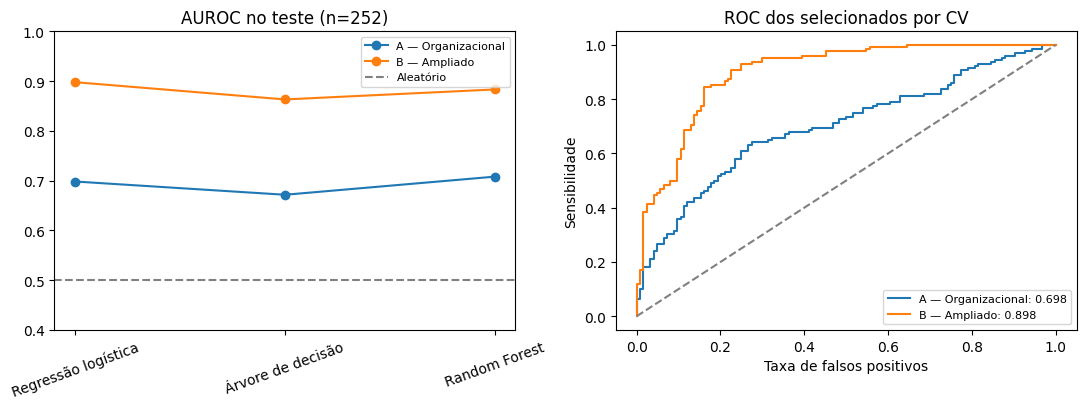

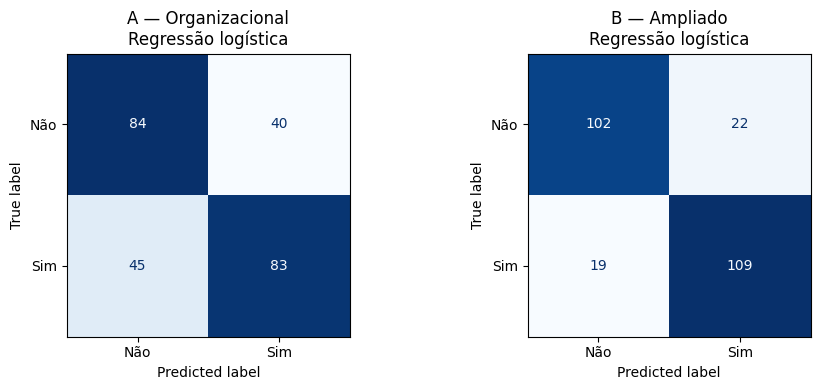

In [7]:
bestA=max([k for k in fitted if k[0]=='A — Organizacional'],key=lambda k:best_cv[k])
bestB=max([k for k in fitted if k[0]=='B — Ampliado'],key=lambda k:best_cv[k])
print('Melhor por AUROC de validação: A=',bestA[1],'B=',bestB[1])

fig,axs=plt.subplots(1,2,figsize=(11,4.2))
for exp,part in results_df.groupby('Experimento',sort=False):
    axs[0].plot(part['Modelo'],part['AUROC'],'o-',label=exp)
axs[0].axhline(0.5,color='gray',linestyle='--',label='Aleatório')
axs[0].set_ylim(.4,1);axs[0].set_title('AUROC no teste (n=252)');axs[0].tick_params(axis='x',rotation=20);axs[0].legend(fontsize=8)
for key in (bestA,bestB):
    fpr,tpr,_=roc_curve(y_test,probabilities[key]);area=roc_auc_score(y_test,probabilities[key])
    axs[1].plot(fpr,tpr,label=f'{key[0]}: {area:.3f}')
axs[1].plot([0,1],[0,1],ls='--',color='gray');axs[1].set(xlabel='Taxa de falsos positivos',ylabel='Sensibilidade',title='ROC dos selecionados por CV');axs[1].legend(fontsize=8)
plt.tight_layout();fig.savefig(FIGS/'02_modelos_roc.png',dpi=180,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(9.5,4))
for ax,key in zip(axs,(bestA,bestB)):
    pred=(probabilities[key]>=.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=['Não','Sim'],cmap='Blues',ax=ax,colorbar=False)
    ax.set_title(key[0]+'\n'+key[1])
plt.tight_layout();fig.savefig(FIGS/'03_matrizes_confusao.png',dpi=180,bbox_inches='tight');plt.show()


## 8. Incerteza e análise de sensibilidade

Intervalos percentílicos de 95% da AUROC no conjunto de teste por **bootstrap estratificado apenas implicitamente pelo reamostrador** (descartamos iterações sem ambas as classes); são estimativas exploratórias condicionadas ao único teste e não substituem validação externa. O intervalo para a diferença entre A e B utiliza **reamostragem pareada** das mesmas observações.

**Ablação:** retirar apenas `work_interfere` do modelo ampliado e reavaliar com CV de treino + teste reservado. Isso testa a dependência de uma resposta condicional à percepção de condição mental.

In [8]:
auc_a=bootstrap_auc(y_test,probabilities[bestA]);auc_b=bootstrap_auc(y_test,probabilities[bestB]);
diff=bootstrap_auc_diff(y_test,probabilities[bestB],probabilities[bestA])
print('IC95% AUROC (A):',auc_a,'(B):',auc_b,'diferença B-A:',diff)

# Ablação: abordagem fixa (LR); tuning somente nos folds de treino.
model_abl,grid_abl=candidates(FULL_WITHOUT_INTERFERENCE)['Regressão logística']
search_abl=GridSearchCV(model_abl,grid_abl,scoring='roc_auc',cv=cv,n_jobs=1,refit=True)
search_abl.fit(df.iloc[idx_train][FULL_WITHOUT_INTERFERENCE],y_train)
p_abl=search_abl.best_estimator_.predict_proba(df.iloc[idx_test][FULL_WITHOUT_INTERFERENCE])[:,1]
abl=evaluate(y_test,p_abl)
print('Ablacao sem work_interfere (LR):', {k:round(v,3) for k,v in abl.items() if isinstance(v,float)})


IC95% AUROC (A): [0.6292854412533038, 0.7630142232358778] (B): [0.8575475044422046, 0.9333823755795422] diferença B-A: [0.1339642311873487, 0.26265410140470125]


Ablacao sem work_interfere (LR): {'AUROC': 0.758, 'AUPRC': 0.765, 'Acurácia': 0.714, 'Precisão': 0.733, 'Recall': 0.688, 'F1': 0.71}


## 9. Curvas de aprendizagem e interpretação de atributos

As arquiteturas selecionadas não são redes neurais com épocas. Por isso, para evidenciar o comportamento durante o treinamento exigido pelo professor, usamos **curvas de aprendizagem (AUROC vs. tamanho do treino)** calculadas somente sobre os dados de treino via CV. Não confundir os pontos da curva com “épocas” de otimização de gradiente. A relevância dos atributos é explorada com **permutation importance de colunas originais**. Essas associações **não são causas** nem justificam classificação de colaboradores.

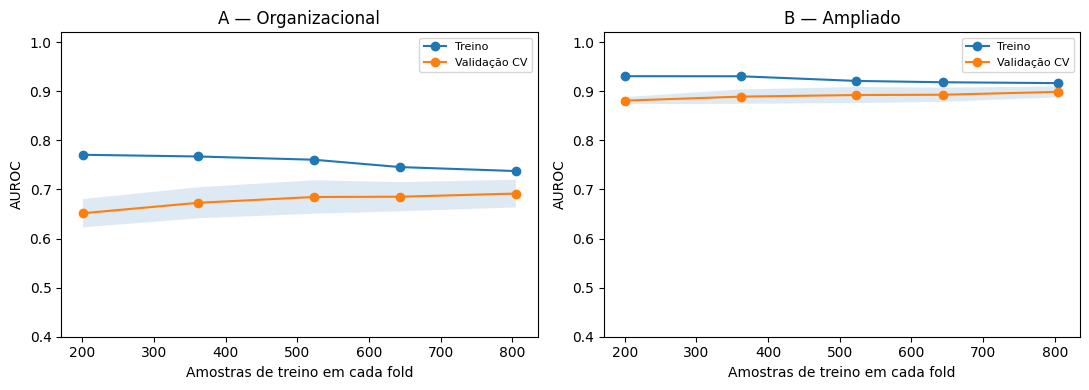

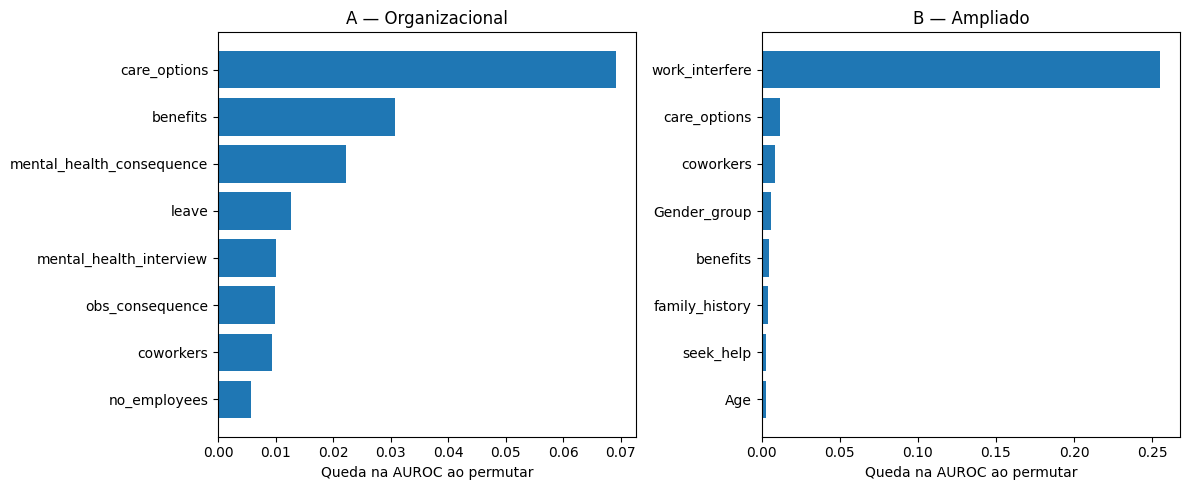

In [9]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,key in zip(axs,(bestA,bestB)):
    cols=experiments[key[0]]
    sizes,tr,va=learning_curve(fitted[key],df.iloc[idx_train][cols],y_train,
             train_sizes=[.25,.45,.65,.8,1.0],cv=cv,scoring='roc_auc',n_jobs=1)
    ax.plot(sizes,tr.mean(axis=1),'-o',label='Treino')
    ax.plot(sizes,va.mean(axis=1),'-o',label='Validação CV')
    ax.fill_between(sizes,va.mean(axis=1)-va.std(axis=1),va.mean(axis=1)+va.std(axis=1),alpha=.15)
    ax.set(title=key[0],xlabel='Amostras de treino em cada fold',ylabel='AUROC',ylim=(.4,1.02))
    ax.legend(fontsize=8)
plt.tight_layout();fig.savefig(FIGS/'04_curvas_aprendizado.png',dpi=180,bbox_inches='tight');plt.show()

fig, axs=plt.subplots(1,2,figsize=(12,5))
importances={}
for ax,key in zip(axs,(bestA,bestB)):
    cols=experiments[key[0]]
    perm=permutation_importance(fitted[key],df.iloc[idx_test][cols],y_test,
           scoring='roc_auc',n_repeats=12,random_state=SEED,n_jobs=1)
    series=pd.Series(perm.importances_mean,index=cols).sort_values(ascending=False)
    importances[key[0]]=series.to_dict()
    top=series.head(8).sort_values()
    ax.barh(top.index,top.values);ax.set(xlabel='Queda na AUROC ao permutar',title=key[0])
plt.tight_layout();fig.savefig(FIGS/'05_importancia_permutacao.png',dpi=180,bbox_inches='tight');plt.show()


## 10. Verificação exploratória por país e discussão de limites

Como a variável `Country` foi excluída dos modelos, ainda podemos comparar a discriminação **no teste** para respondentes dos EUA e dos demais países. Subgrupos pequenos/selecionados não permitem afirmar equidade ou transportabilidade.

**Limitações essenciais:** amostragem voluntária e não probabilística; autorrelato; desenho transversal sem ordem temporal entre trabalho/tratamento; possíveis múltiplas respostas da mesma pessoa; percepções atuais influenciadas por tratamento prévio (*reverse causation*); `work_interfere` condicionada à condição mental; falta de validação externa. A pesquisa não permite inferência causal nem estimar risco individual de transtorno mental.

In [10]:
for label,mask in [('EUA',df.iloc[idx_test]['Country'].eq('United States').to_numpy()),
                   ('Outros países',~df.iloc[idx_test]['Country'].eq('United States').to_numpy())]:
    yy=y_test.to_numpy()[mask]; pp=probabilities[bestA][mask]
    print(label, 'n=',sum(mask),'positivos=',sum(yy),
          'AUROC A=',round(roc_auc_score(yy,pp),3) if len(set(yy))==2 else 'não estimável')

export={
 'n_original':len(raw), 'n_analysis':len(df), 'invalid_ages_imputed':int((~raw['Age'].between(18,90)).sum()),
 'target_yes':int(sum(y)), 'target_no':int(len(y)-sum(y)),
 'n_train':len(idx_train),'n_test':len(idx_test),
 'train_yes':int(sum(y_train)),'test_yes':int(sum(y_test)),
 'features_A':ORGANIZATIONAL,'features_B':FULL,
 'best_A':{'algorithm':bestA[1], 'cv_auc':best_cv[bestA], 'metrics':evaluate(y_test,probabilities[bestA]),'auc_ci95':auc_a},
 'best_B':{'algorithm':bestB[1], 'cv_auc':best_cv[bestB], 'metrics':evaluate(y_test,probabilities[bestB]),'auc_ci95':auc_b},
 'auc_diff_b_minus_a_ci95':diff, 'ablation_no_work_interfere_logistic':abl,
 'feature_importances':importances,
 'all_models':results_df.to_dict(orient='records')}
with open(OUTPUT/'resultados.json','w',encoding='utf-8') as fp:json.dump(export,fp,indent=2,ensure_ascii=False)
print('Resultados salvos em',OUTPUT/'resultados.json')


EUA n= 146 positivos= 80 AUROC A= 0.7
Outros países n= 106 positivos= 48 AUROC A= 0.685
Resultados salvos em resultados/resultados.json


## 10. Evolução de desempenho com o aumento do número de árvores (Random Forest)

Para atender à solicitação de acompanhar o comportamento da execução, medimos a AUROC ao variar o número de árvores de uma Random Forest. Criamos uma subdivisão **somente dentro do treinamento** (80/20 interno) e visualizamos treino versus validação interna. **O eixo representa número de árvores, não número de épocas; não usamos esse gráfico para escolher modelos no teste final.**

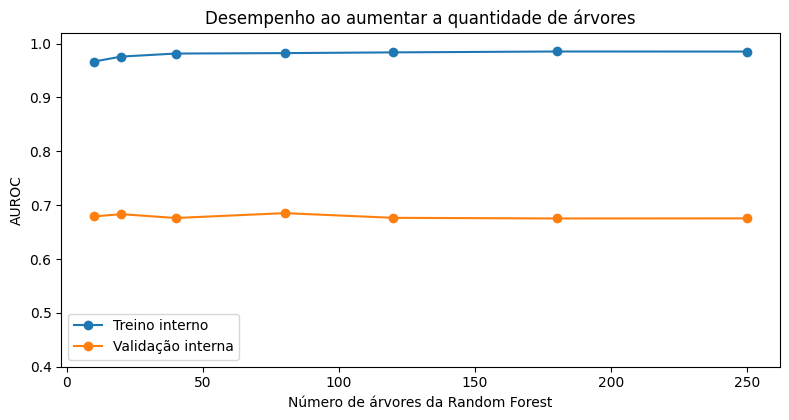

AUROC por número de árvores (validação interna): {10: np.float64(0.679), 20: np.float64(0.683), 40: np.float64(0.676), 80: np.float64(0.685), 120: np.float64(0.676), 180: np.float64(0.675), 250: np.float64(0.675)}


In [11]:
from sklearn.ensemble import RandomForestClassifier
from src.modeling import build_pipeline
ix_fit,ix_val=train_test_split(idx_train,test_size=.20,stratify=y.iloc[idx_train],random_state=SEED+1)
ntrees=[10,20,40,80,120,180,250]
auc_train=[];auc_val=[]
for ntrees_i in ntrees:
    est=build_pipeline(RandomForestClassifier(n_estimators=ntrees_i,max_depth=12,
          min_samples_leaf=2,random_state=SEED,n_jobs=1),ORGANIZATIONAL)
    est.fit(df.iloc[ix_fit][ORGANIZATIONAL],y.iloc[ix_fit])
    auc_train.append(roc_auc_score(y.iloc[ix_fit],est.predict_proba(df.iloc[ix_fit][ORGANIZATIONAL])[:,1]))
    auc_val.append(roc_auc_score(y.iloc[ix_val],est.predict_proba(df.iloc[ix_val][ORGANIZATIONAL])[:,1]))
fig,ax=plt.subplots(figsize=(8,4.3))
ax.plot(ntrees,auc_train,'-o',label='Treino interno')
ax.plot(ntrees,auc_val,'-o',label='Validação interna')
ax.set(xlabel='Número de árvores da Random Forest',ylabel='AUROC',title='Desempenho ao aumentar a quantidade de árvores',ylim=(.4,1.02))
ax.legend();plt.tight_layout();fig.savefig(FIGS/'06_evolucao_numero_arvores.png',dpi=180,bbox_inches='tight');plt.show()
print('AUROC por número de árvores (validação interna):',dict(zip(ntrees,np.round(auc_val,3))))


## 11. Conclusão e aplicações responsáveis

O experimento A mede associações preditivas entre percepções/condições de trabalho e histórico autorrelatado de tratamento; o B investiga o sinal adicional de características individuais. Os resultados são **retrospectivos**, obtidos em respostas à OSMI 2014, e não constituem avaliação clínica, diagnóstico, prognóstico validado, indicação de tratamento, nem ferramenta de triagem ou seleção de empregados. Para qualquer uso operacional seriam indispensáveis validação externa/prospectiva, consentimento, governança de dados e análise ética. 

Arquivos produzidos para o artigo LaTeX: `resultados/resultados.json`, `resultados/metricas_modelos.csv` e `artigo/figuras/01..05_*.png`. O artigo utiliza esses valores efetivamente produzidos.